# Kaplan-Meier and Nelson-Aalen estimators with `lifelines`

The same estimators of the previous notebook, now with the library `lifelines`: the Kaplan-Meier estimator of the survivor function, the Nelson-Aalen estimator of the cumulative hazard, a smoothed estimate of the hazard function, and the median time.

The data are the times, in weeks, to discontinuation of the use of an intrauterine device (IUD) for 18 women (`status` is 1 for an observed discontinuation and 0 for a censored time).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lifelines import KaplanMeierFitter, NelsonAalenFitter
from lifelines.utils import median_survival_times, qth_survival_time
from ipywidgets import interact, IntSlider

In [2]:
ALPHA=0.05

In [3]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
opt_color   = '#E69F00'

ci_label = f'{(1 - ALPHA) * 100:.0f}% confidence interval'

## The data

In [4]:
DatOriginal = pd.read_csv("data/iud_discontinuation.dat", sep=r"\s+")

In [5]:
DatOriginal.head()

,time,status
0,10,1
1,13,0
2,18,0
3,19,1
4,23,0


Function for the plots: an estimator of `lifelines` (a step function) with its confidence interval.

In [6]:
def PlotEstimate(ax, estimate, interval, label):
    ax.fill_between(interval.index, interval.iloc[:, 0], interval.iloc[:, 1], step='post', color=ci_color, alpha=0.7,
                    label=ci_label)
    ax.step(estimate.index, estimate.iloc[:, 0], where='post', color=line_color, lw=2, label=label)
    ax.set_xlabel('Time (weeks)')
    ax.set_xlim(0, None)
    ax.grid(True, alpha=0.25)

## Kaplan-Meier estimator

In [7]:
kmf = KaplanMeierFitter(alpha=ALPHA)
kmf.fit(DatOriginal['time'], event_observed=DatOriginal['status'])

<lifelines.KaplanMeierFitter:"KM_estimate", fitted with 18 total observations, 9 right-censored observations>

The event table is the life-table of the previous notebook: individuals at risk, events and censored times at each time.

In [8]:
kmf.event_table

,removed,observed,censored,entrance,at_risk
event_at,,,,,
0.0,0,0,0,18,18
10.0,1,1,0,0,18
13.0,1,0,1,0,17
18.0,1,0,1,0,16
19.0,1,1,0,0,15
23.0,1,0,1,0,14
30.0,1,1,0,0,13
36.0,1,1,0,0,12
38.0,1,0,1,0,11


In [9]:
pd.concat([kmf.survival_function_, kmf.confidence_interval_], axis=1).round(4)

,KM_estimate,KM_estimate_lower_0.95,KM_estimate_upper_0.95
0.0,1.0000,1.0000,1.0000
10.0,0.9444,0.6664,0.9920
13.0,0.9444,0.6664,0.9920
18.0,0.9444,0.6664,0.9920
19.0,0.8815,0.6019,0.9691
23.0,0.8815,0.6019,0.9691
30.0,0.8137,0.5241,0.9363
36.0,0.7459,0.4536,0.8970
38.0,0.7459,0.4536,0.8970
54.0,0.7459,0.4536,0.8970


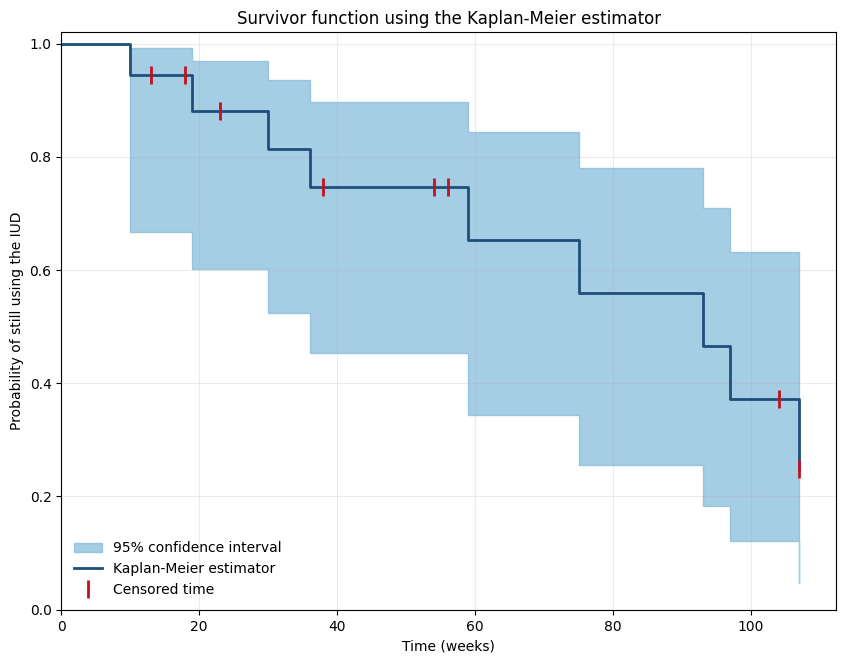

In [10]:
fig, ax = plt.subplots(figsize=(10, 7.5))
PlotEstimate(ax, kmf.survival_function_, kmf.confidence_interval_, 'Kaplan-Meier estimator')

# A tick on the curve at each censored time
Censored = kmf.event_table.index[kmf.event_table['censored'] > 0]
ax.plot(Censored, kmf.survival_function_.loc[Censored, 'KM_estimate'], '|', color=point_color, markersize=13,
        markeredgewidth=2, label='Censored time')

ax.set_ylabel('Probability of still using the IUD')
ax.set_ylim(0, 1.02)
ax.set_title('Survivor function using the Kaplan-Meier estimator')
ax.legend(loc='lower left', frameon=False)

## Nelson-Aalen estimator

In [11]:
naf = NelsonAalenFitter(alpha=ALPHA)
naf.fit(DatOriginal['time'], event_observed=DatOriginal['status'])

<lifelines.NelsonAalenFitter:"NA_estimate", fitted with 18 total observations, 9 right-censored observations>

In [12]:
pd.concat([naf.cumulative_hazard_, naf.confidence_interval_], axis=1).round(4)

,NA_estimate,NA_estimate_lower_0.95,NA_estimate_upper_0.95
0.0,0.0000,0.0000,0.0000
10.0,0.0556,0.0078,0.3944
13.0,0.0556,0.0078,0.3944
18.0,0.0556,0.0078,0.3944
19.0,0.1222,0.0304,0.4915
23.0,0.1222,0.0304,0.4915
30.0,0.1991,0.0636,0.6235
36.0,0.2825,0.1049,0.7608
38.0,0.2825,0.1049,0.7608
54.0,0.2825,0.1049,0.7608


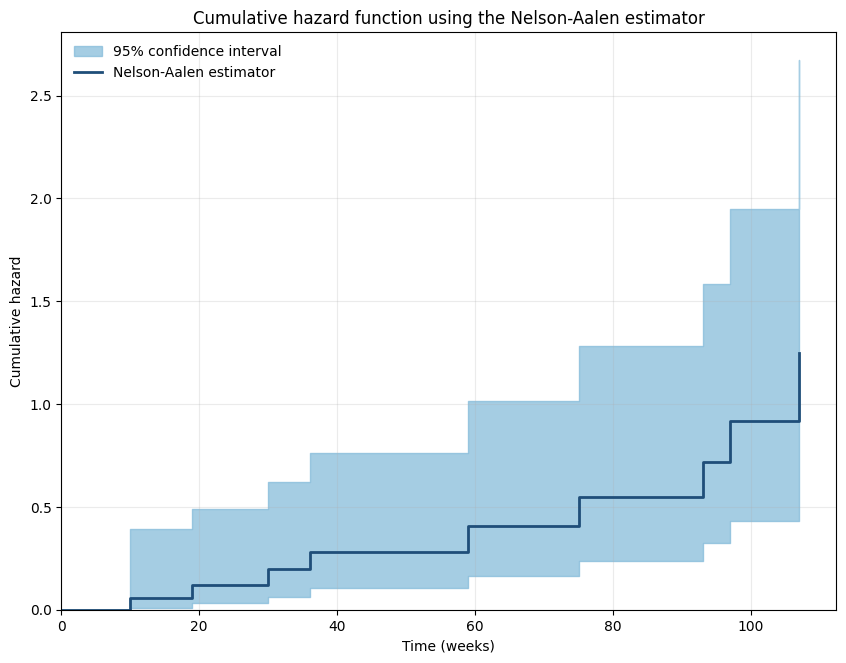

In [13]:
fig, ax = plt.subplots(figsize=(10, 7.5))
PlotEstimate(ax, naf.cumulative_hazard_, naf.confidence_interval_, 'Nelson-Aalen estimator')

ax.set_ylabel('Cumulative hazard')
ax.set_ylim(0, None)
ax.set_title('Cumulative hazard function using the Nelson-Aalen estimator')
ax.legend(loc='upper left', frameon=False)

## Hazard function

The hazard is the derivative of the cumulative hazard, and the Nelson-Aalen estimator is a step function, so it has to be smoothed. `lifelines` uses a kernel: the estimate at time $t$ uses the jumps of the cumulative hazard between $t-b$ and $t+b$, where $b$ is the bandwidth. A small bandwidth gives an irregular estimate, a large one a very smooth estimate that hides the changes.

In [14]:
def PlotHazard(ax, bandwidth, legend=True):
    hazard = naf.smoothed_hazard_(bandwidth)
    interval = naf.smoothed_hazard_confidence_intervals_(bandwidth)
    ax.fill_between(interval.index, interval.iloc[:, 0], interval.iloc[:, 1], color=ci_color, alpha=0.7, label=ci_label)
    ax.plot(hazard.index, hazard.iloc[:, 0], color=line_color, lw=2, label='Smoothed hazard')
    ax.set_xlabel('Time (weeks)')
    ax.set_ylabel('Hazard (events per woman per week)')
    ax.set_xlim(0, None)
    ax.set_ylim(0, 0.06)
    ax.set_title(f'Bandwidth of {bandwidth} weeks')
    ax.grid(True, alpha=0.25)
    if legend:
        ax.legend(loc='upper left', frameon=False)

Move the slider to change the bandwidth (this cell needs a running kernel).

In [15]:
def interactive_hazard(bandwidth):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    PlotHazard(ax, bandwidth)
    plt.show()

interact(interactive_hazard, bandwidth=IntSlider(value=25, min=5, max=60, step=5, description='bandwidth'));

interactive(children=(IntSlider(value=25, description='bandwidth', max=60, min=5, step=5), Output()), _dom_cla…

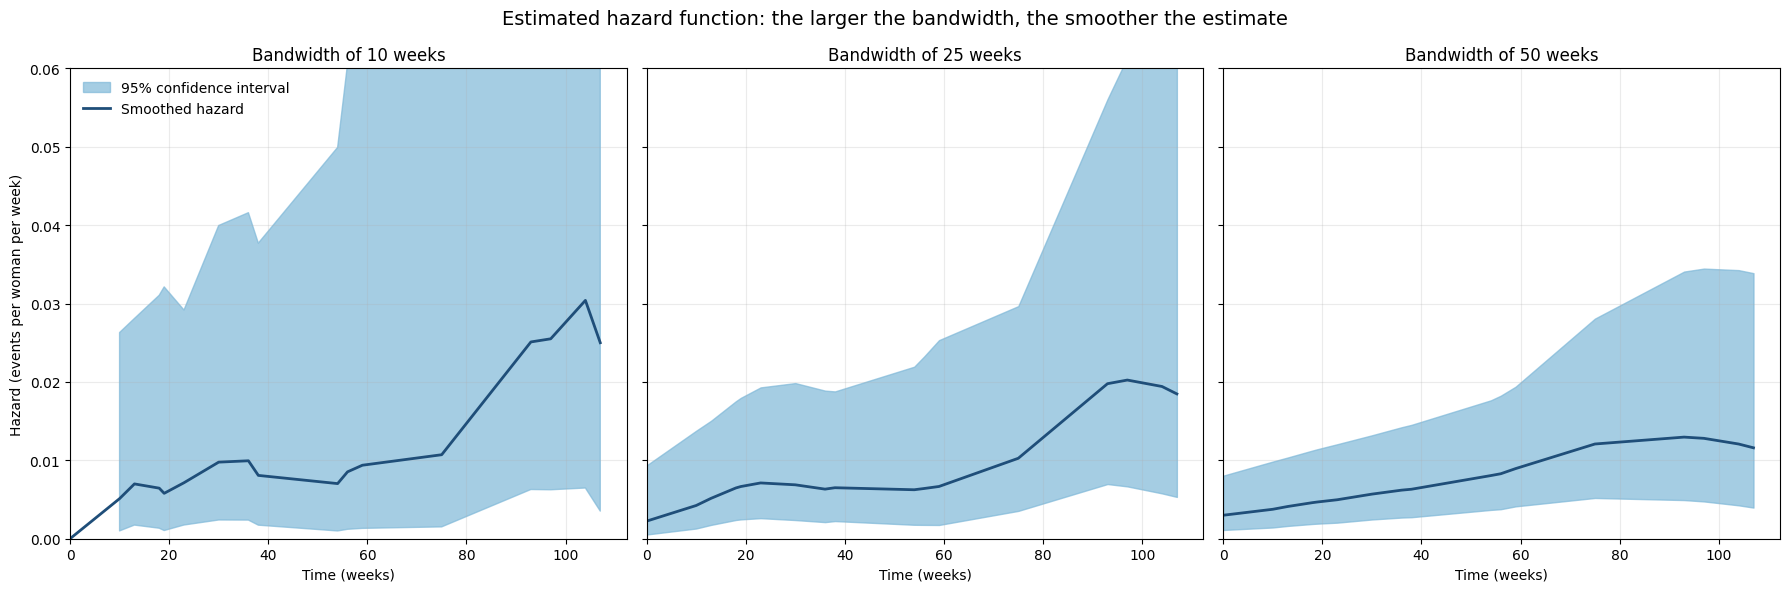

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, bandwidth in zip(axes, [10, 25, 50]):
    PlotHazard(ax, bandwidth, legend=(bandwidth == 10))
for ax in axes[1:]:
    ax.set_ylabel('')
fig.suptitle('Estimated hazard function: the larger the bandwidth, the smoother the estimate', fontsize=14)
plt.tight_layout()

## Median estimator

The median is the first time at which the Kaplan-Meier estimator is 0.5 or less. Its confidence interval is formed by the times at which the limits of the confidence interval of the survivor function cross 0.5; the upper limit never goes below 0.5 here, so the interval has no upper end.

In [17]:
kmf.median_survival_time_

np.float64(93.0)

In [18]:
median_survival_times(kmf.confidence_interval_)

,KM_estimate_lower_0.95,KM_estimate_upper_0.95
0.5,36.0,inf


In [19]:
qth_survival_time(0.5, kmf.survival_function_)

np.float64(93.0)

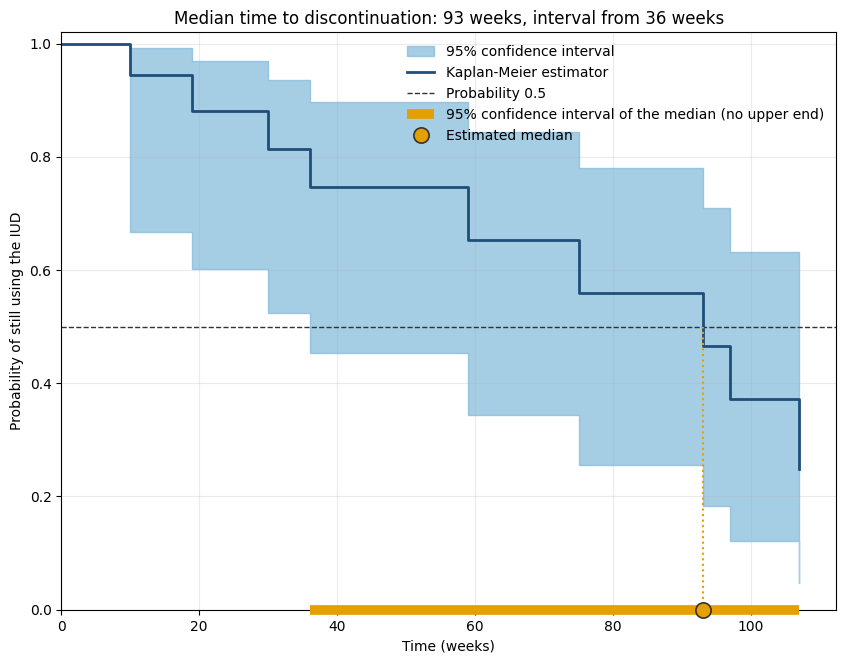

In [20]:
MedianInterval = median_survival_times(kmf.confidence_interval_).iloc[0]

fig, ax = plt.subplots(figsize=(10, 7.5))
PlotEstimate(ax, kmf.survival_function_, kmf.confidence_interval_, 'Kaplan-Meier estimator')
ax.axhline(0.5, color='#333333', lw=1, ls='--', label='Probability 0.5')
ax.vlines(kmf.median_survival_time_, 0, 0.5, color=opt_color, lw=1.5, ls=':')
ax.plot([MedianInterval.iloc[0], kmf.survival_function_.index.max()], [0, 0], color=opt_color, lw=7,
        solid_capstyle='butt', clip_on=False, zorder=5, label=ci_label + ' of the median (no upper end)')
ax.plot(kmf.median_survival_time_, 0, 'o', color=opt_color, markersize=11, markeredgecolor='#333333',
        markeredgewidth=1.2, clip_on=False, zorder=6, label='Estimated median')

ax.set_ylabel('Probability of still using the IUD')
ax.set_ylim(0, 1.02)
ax.set_title(f'Median time to discontinuation: {kmf.median_survival_time_:.0f} weeks, '
             f'interval from {MedianInterval.iloc[0]:.0f} weeks')
ax.legend(loc='upper right', frameon=False)